# 01 - Data and features

This notebook loads the order files and the BTC 1-minute prices, checks them, and builds the features.
Every feature uses only BTC minutes that ended **before** the order was created (see `pricing/features.py`
and the no-look-ahead test in `tests/test_data_features.py`).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

In [2]:
from pricing.data import load_orders, load_btc
from pricing.features import market_features, order_features

train = load_orders("train")
valid = load_orders("valid")
btc = load_btc()
print(f"training orders: {len(train):,}   validation orders: {len(valid):,}")
print(f"BTC minutes: {len(btc):,}  from {btc.index.min()} to {btc.index.max()}")

training orders: 7,204   validation orders: 4,155
BTC minutes: 412,080  from 2026-01-01 00:00:00 to 2026-10-14 03:59:00


## Data checks

- The validation file has two date formats. Rows from July and August have no seconds ("minute only").
- The validation file contains the closing time. It is known only after an order ends, so it is **never** used.
- Jasper's base price is missing for some orders, and for **all** orders in September and October.

In [3]:
def coverage(df):
    g = df.groupby(df["created"].dt.to_period("M"))
    return pd.DataFrame({
        "orders": g.size(),
        "with base price %": g["base"].apply(lambda s: s.notna().mean() * 100),
        "with result %": g["has_outcome"].mean() * 100,
        "minute-only time %": g["created_minute_only"].mean() * 100,
    }).round(1)

pd.concat({"training": coverage(train), "validation": coverage(valid)})

orders  with base price %  with result %  minute-only time %
           created                                                              
training   2026-02     228            100.000         92.500               0.000
           2026-03     293            100.000         90.800               0.000
           2026-04     877            100.000         98.900               0.000
           2026-05     965             75.400        100.000               0.000
           2026-06    2270             60.600        100.000               0.000
           2026-07    2571            100.000        100.000               0.000
validation 2026-07     118            100.000          0.000             100.000
           2026-08    2129             86.500          0.000              83.600
           2026-09    1340              0.000          0.000               0.000
           2026-10     568              0.000          0.000               0.000

In [4]:
print("validation rows with a closing time (post-trade information, not used):", valid["post_closed"].notna().sum())
print("validation rows with Jasper's real price (base + markup given):", valid["paid"].notna().sum())
print("training rows without a result (excluded from fitting):", (~train["has_outcome"]).sum())

validation rows with a closing time (post-trade information, not used): 4155
validation rows with Jasper's real price (base + markup given): 544
training rows without a result (excluded from fitting): 54


## Features

In [5]:
mkt = market_features(btc)
X_train = order_features(train, mkt)
X_valid = order_features(valid, mkt)
missing = pd.concat({"training": X_train.isna().sum(), "validation": X_valid.isna().sum()}, axis=1)
print("columns with missing values:")
missing[missing.sum(axis=1) > 0]

columns with missing values:


,training,validation


In [6]:
X_train.to_parquet(OUT / "features_train.parquet")
X_valid.to_parquet(OUT / "features_valid.parquet")
X_train.describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
spot,"67,152.413","64,690.000","58,113.400","82,615.500"
rv15,0.460,0.374,0.054,3.568
rv60,0.456,0.388,0.083,2.397
rv240,0.423,0.378,0.106,2.272
rv1440,0.419,0.393,0.128,1.628
rv10080,0.412,0.396,0.270,1.042
pk60,0.418,0.359,0.066,2.565
pk1440,0.381,0.360,0.101,1.578
ret15,-0.000,-0.000,-0.033,0.025
ret60,-0.000,-0.000,-0.064,0.045


## First look: payouts against Jasper's base price

Ratio = total payout / total (base price x size). A ratio above 1 means the base price was too low.

In [7]:
d = train[train["has_outcome"] & train["base"].notna()].copy()
d["month"] = d["created"].dt.to_period("M").astype(str)
def ratios(g):
    base_usd = (g["base"] * g["qty"]).sum()
    return pd.Series({"orders": len(g), "payout / base": g["post_payout_usd"].sum() / base_usd,
                      "Jasper price / base": (g["paid"] * g["qty"]).sum() / base_usd})
by_month = d.groupby("month").apply(ratios, include_groups=False)
by_duration = d.groupby("duration_s").apply(ratios, include_groups=False)
display(by_month.round(2)); display(by_duration.round(2))
by_month.to_csv(OUT / "eda_ratio_by_month.csv"); by_duration.to_csv(OUT / "eda_ratio_by_duration.csv")

,orders,payout / base,Jasper price / base
month,,,
2026-02,211.000,1.970,1.400
2026-03,266.000,1.530,1.600
2026-04,867.000,1.070,1.410
2026-05,728.000,1.090,1.330
2026-06,"1,376.000",1.490,1.390
2026-07,"2,571.000",1.440,1.500


,orders,payout / base,Jasper price / base
duration_s,,,
1800,"2,678.000",1.450,1.940
3600,487.000,1.520,1.600
7200,893.000,1.230,1.400
14400,954.000,1.550,1.320
28800,808.000,1.290,1.280
43200,46.000,1.180,1.450
86400,153.000,0.460,1.270


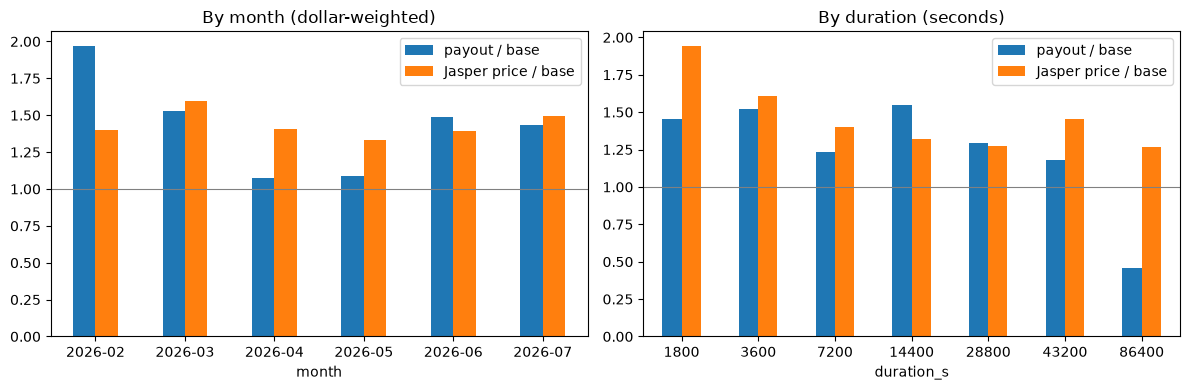

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
by_month[["payout / base", "Jasper price / base"]].plot.bar(ax=ax[0], rot=0)
ax[0].axhline(1, color="grey", lw=0.8); ax[0].set_title("By month (dollar-weighted)")
by_duration[["payout / base", "Jasper price / base"]].plot.bar(ax=ax[1], rot=0)
ax[1].axhline(1, color="grey", lw=0.8); ax[1].set_title("By duration (seconds)")
plt.tight_layout(); plt.show()